# 🥔 Irish Potato Leaf Disease Classification — End-to-End ML Pipeline

**Goal:** classify a potato leaf photo as **Early blight**, **Late blight** or **Healthy** (the class list is read from your dataset folders, so other class sets also work).

This notebook covers the offline half of the MLOps pipeline:

| Step | Section |
|---|---|
| Data acquisition (you upload the dataset, only the 3 potato classes are kept, everything is saved to Google Drive) | 1–2 |
| Exploratory analysis + feature interpretation | 3 |
| Data preprocessing (resize, scale, augmentation, class weights) | 4 |
| Model creation — **custom CNN trained from scratch** (no pretrained backbone) | 5 |
| Optimisation: L2 regularisation, dropout, batch-norm, optimiser comparison, early stopping, LR scheduling | 5–6 |
| Evaluation: accuracy, loss, precision, recall, F1, ROC-AUC, confusion matrix | 7 |
| Saving the model (`.h5`) + artefacts for the API | 8 |
| Prediction functions | 9 |
| Retraining using the saved custom model as the pre-trained model | 10 |

> **Runtime:** in Colab choose *Runtime → Change runtime type → T4 GPU* before running.

## 0. Setup

In [1]:
import os, sys, json, glob, shutil, random, zipfile, time
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFilter
import tensorflow as tf
from tensorflow.keras import layers, regularizers
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IN_COLAB = "google.colab" in sys.modules
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none", "| Colab:", IN_COLAB)
print("👉 Use the same TensorFlow version in requirements.txt of the API (tensorflow-cpu==%s)" % tf.__version__)

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | Colab: True
👉 Use the same TensorFlow version in requirements.txt of the API (tensorflow-cpu==2.21.0)


### Configuration
Change these values if needed. `UPLOAD_METHOD` decides how **you** provide the dataset:

* `"drive_zip"` – (recommended) upload your dataset `.zip` to Google Drive first and set `DATASET_ZIP_ON_DRIVE`.
* `"upload_zip"` – a file picker appears and you upload the `.zip` from your computer (fine for small zips).
* `"drive_folder"` – the dataset is already extracted somewhere on Drive; set `DATASET_FOLDER_ON_DRIVE`.

The zip/folder can be organised either as `class_name/image.jpg` **or** with existing splits such as
`Training/<class>/…`, `Validation/<class>/…`, `Testing/<class>/…` — both are detected automatically.

**PlantVillage users:** the Kaggle *PlantVillage* dataset contains 15 folders (Pepper, Potato and Tomato).
`CLASS_PREFIX = "Potato"` keeps only `Potato___Early_blight`, `Potato___Late_blight` and `Potato___healthy`
and ignores everything else, so the model is a pure Irish potato classifier.

In [5]:
# ---------------- where everything is stored ----------------
DRIVE_PROJECT_DIR = "/content/drive/MyDrive/potato_leaf_mlops"   # all data/models/plots/metrics go here

# ---------------- how you provide the dataset ----------------
UPLOAD_METHOD = "upload_zip"            # "drive_zip" | "upload_zip" | "drive_folder"
DATASET_ZIP_ON_DRIVE = "/content/drive/MyDrive/potato_dataset.zip"
DATASET_FOLDER_ON_DRIVE = "/content/drive/MyDrive/PotatoLeafDataset"
REBUILD_SPLITS = False                 # True = re-extract and re-split even if Drive already has data
CLASS_PREFIX = "Potato"                # keep only class folders starting with this (PlantVillage also has Pepper + Tomato)
                                       # set to "" to keep every class folder

# ---------------- training hyper-parameters ----------------
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 50                  # max epochs (early stopping usually ends sooner)
SEARCH_EPOCHS = 8            # epochs per candidate in the optimiser comparison
BASELINE_EPOCHS = 15
RUN_BASELINE = True          # train an un-optimised CNN for comparison
RUN_OPTIMIZER_SEARCH = True  # compare Adam / RMSprop / SGD and pick the best
VAL_FRACTION, TEST_FRACTION = 0.15, 0.15

## 1. Mount Google Drive

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
else:  # running locally: keep the same layout in a local folder
    DRIVE_PROJECT_DIR = os.environ.get("LOCAL_PROJECT_DIR", "./potato_leaf_mlops")

PROJECT = Path(DRIVE_PROJECT_DIR)
DATA_DIR, MODELS_DIR = PROJECT / "data", PROJECT / "models"
PLOTS_DIR, NEW_DATA_DIR = MODELS_DIR / "plots", PROJECT / "new_data"
for d in (DATA_DIR, MODELS_DIR, PLOTS_DIR, NEW_DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Training reads from a fast local copy; Drive keeps the permanent copy.
WORK = Path("/content/work") if IN_COLAB else Path(os.environ.get("LOCAL_WORK_DIR", "./work"))
WORK.mkdir(parents=True, exist_ok=True)
print("Saving everything to:", PROJECT.resolve())

Mounted at /content/drive
Saving everything to: /content/drive/MyDrive/potato_leaf_mlops


## 2. Data acquisition
You provide the dataset (no hard-coded download). The images are verified, split into
**train / validation / test** with stratification, and saved to `DRIVE_PROJECT_DIR/data/`.
On later runs the split is loaded straight from Drive, so you only upload once.

In [6]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def is_image(p): return Path(p).suffix.lower() in IMG_EXTS

def get_raw_dataset() -> Path:
    raw = WORK / "raw"
    if raw.exists(): shutil.rmtree(raw)
    raw.mkdir(parents=True)

    # Fallback if the drive zip is configured but missing
    method = UPLOAD_METHOD
    if method == "drive_zip" and not Path(DATASET_ZIP_ON_DRIVE).exists():
        print(f"⚠️ Warning: '{DATASET_ZIP_ON_DRIVE}' was not found on your Google Drive.")
        print("Switching to 'upload_zip' method so you can upload it manually.")
        method = "upload_zip"

    if method == "upload_zip":
        from google.colab import files
        uploaded = files.upload()                       # choose your dataset .zip
        zip_name = next(iter(uploaded))
        shutil.copy(zip_name, PROJECT / "dataset_upload.zip")   # keep a copy on Drive
        zipfile.ZipFile(zip_name).extractall(raw)
    elif method == "drive_zip":
        print("Extracting", DATASET_ZIP_ON_DRIVE)
        zipfile.ZipFile(DATASET_ZIP_ON_DRIVE).extractall(raw)
    elif method == "drive_folder":
        if not Path(DATASET_FOLDER_ON_DRIVE).exists():
            raise FileNotFoundError(f"Dataset folder not found at {DATASET_FOLDER_ON_DRIVE}")
        shutil.copytree(DATASET_FOLDER_ON_DRIVE, raw / "dataset")
    else:
        raise ValueError(method)
    return raw

SPLIT_ALIASES = {"train": "train", "training": "train", "val": "val", "valid": "val",
                 "validation": "val", "test": "test", "testing": "test"}

def scan_dataset(raw: Path):
    # Map each folder that directly holds images to (split or None, class name).
    records = []
    for d in sorted(p for p in raw.rglob("*") if p.is_dir()):
        if "__MACOSX" in d.parts: continue
        imgs = [f for f in d.iterdir() if f.is_file() and is_image(f)]
        if not imgs: continue
        split = next((SPLIT_ALIASES[p.lower()] for p in d.relative_to(raw).parts[:-1]
                      if p.lower() in SPLIT_ALIASES), None)
        records += [(str(f), split, d.name) for f in imgs]
    df = pd.DataFrame(records, columns=["path", "split", "folder"])
    # Normalise class names so "Early_Blight" and "early_blight" are the same class
    canon = {}
    for f in df["folder"].unique():
        canon.setdefault(f.lower().replace(" ", "_"), f)
    df["label"] = df["folder"].map(lambda f: canon[f.lower().replace(" ", "_")])
    return filter_classes(df)

def matches_prefix(name):
    return name.lower().startswith(CLASS_PREFIX.lower())

def filter_classes(df):
    # Keep only the potato classes (PlantVillage also ships Pepper + Tomato folders)
    if CLASS_PREFIX and df.label.map(matches_prefix).any():
        dropped = sorted(df.label[~df.label.map(matches_prefix)].unique())
        df = df[df.label.map(matches_prefix)].copy()
        print(f"Keeping classes starting with '{CLASS_PREFIX}':", sorted(df.label.unique()))
        if dropped: print(f"Ignored {len(dropped)} other classes:", dropped)
    elif CLASS_PREFIX:
        print(f"No folder starts with '{CLASS_PREFIX}', keeping all classes:", sorted(df.label.unique()))
    # Some zips contain the same image twice (e.g. PlantVillage/PlantVillage/...): drop duplicates
    # so one image can never end up in both train and test.
    before = len(df)
    df = df.assign(fname=df.path.map(lambda p: Path(p).name)).drop_duplicates(["label", "fname"]).drop(columns="fname")
    if before != len(df): print("Duplicate images removed:", before - len(df))
    return df

def verify(path):
    try:
        with Image.open(path) as im: im.verify()
        return True
    except Exception:
        return False

def stratified_assign(df, fractions):
    # fractions: dict split -> fraction for the rows that have no split yet
    out = []
    for label, g in df.groupby("label"):
        idx = g.sample(frac=1, random_state=SEED).index.tolist()
        n = len(idx); start = 0
        for i, (split, frac) in enumerate(fractions.items()):
            k = n - start if i == len(fractions) - 1 else int(round(n * frac))
            out += [(j, split) for j in idx[start:start + k]]; start += k
    for j, s in out: df.loc[j, "split"] = s
    return df

def build_splits():
    raw = get_raw_dataset()
    df = scan_dataset(raw)
    print(f"Found {len(df)} images in {df.label.nunique()} classes:", sorted(df.label.unique()))
    ok = df.path.map(verify); print("Corrupt/unreadable images removed:", int((~ok).sum()))
    df = df[ok].copy()
    have = set(df.split.dropna().unique())
    if {"train", "test"} <= have and "val" not in have:          # carve validation out of train
        tr = df[df.split == "train"].copy(); tr["split"] = None
        df.update(stratified_assign(tr, {"val": VAL_FRACTION / (1 - TEST_FRACTION), "train": 1}))
    elif {"train", "val"} <= have and "test" not in have:          # carve test out of train
        tr = df[df.split == "train"].copy(); tr["split"] = None
        df.update(stratified_assign(tr, {"test": TEST_FRACTION, "train": 1}))
    elif not {"train", "val", "test"} <= have:                     # no usable split: make 70/15/15
        df["split"] = None
        df = stratified_assign(df, {"val": VAL_FRACTION, "test": TEST_FRACTION, "train": 1})
    for d in ("train", "val", "test"):
        if (WORK / d).exists(): shutil.rmtree(WORK / d)
    for _, r in df.iterrows():
        dst = WORK / r.split / r.label; dst.mkdir(parents=True, exist_ok=True)
        shutil.copy(r.path, dst / Path(r.path).name)
    for d in ("train", "val", "test"):                              # persist on Drive
        if (DATA_DIR / d).exists(): shutil.rmtree(DATA_DIR / d)
        shutil.copytree(WORK / d, DATA_DIR / d)
    shutil.rmtree(raw)

def saved_split_is_stale():
    # Rebuild if the split on Drive still holds non-potato classes from an earlier run
    if not (DATA_DIR / "train").exists() or not any((DATA_DIR / "train").iterdir()):
        return True
    saved = [d.name for d in (DATA_DIR / "train").iterdir() if d.is_dir()]
    if CLASS_PREFIX and any(map(matches_prefix, saved)) and not all(map(matches_prefix, saved)):
        print("Saved split contains other classes:", sorted(c for c in saved if not matches_prefix(c)), "-> rebuilding")
        return True
    return False

if REBUILD_SPLITS or saved_split_is_stale():
    build_splits()
else:
    print("Using the existing split saved on Drive:", DATA_DIR)
    for d in ("train", "val", "test"):
        if (WORK / d).exists(): shutil.rmtree(WORK / d)
        shutil.copytree(DATA_DIR / d, WORK / d)

TRAIN_DIR, VAL_DIR, TEST_DIR = WORK / "train", WORK / "val", WORK / "test"
CLASS_NAMES = sorted(d.name for d in TRAIN_DIR.iterdir() if d.is_dir())
NUM_CLASSES = len(CLASS_NAMES)
def pretty(c): return (c.split("___")[-1] if "___" in c else c).replace("_", " ").strip().capitalize()
DISPLAY = [pretty(c) for c in CLASS_NAMES]
print("Classes:", dict(zip(CLASS_NAMES, DISPLAY)))

Saving potato_dataset.zip.zip to potato_dataset.zip.zip
Keeping classes starting with 'Potato': ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Ignored 12 other classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Found 2152 images in 3 classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Corrupt/unreadable images removed: 0
Classes: {'Potato___Early_blight': 'Early blight', 'Potato___Late_blight': 'Late blight', 'Potato___healthy': 'Healthy'}


## 3. Exploratory data analysis

,train,val,test,total
Early blight,700,150,150,1000
Late blight,700,150,150,1000
Healthy,106,23,23,152


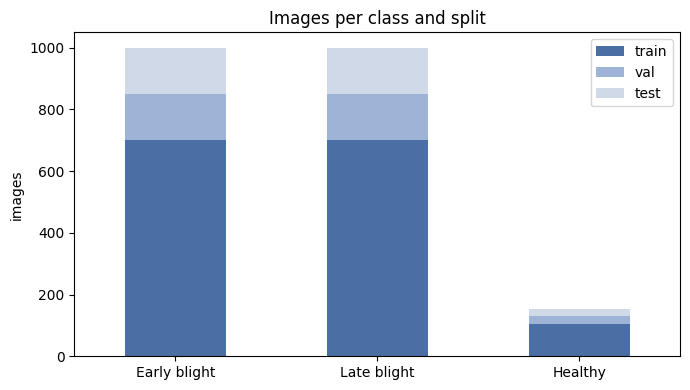

Imbalance ratio (max/min): 6.58


In [7]:
def list_split(directory):
    paths, labels = [], []
    for i, c in enumerate(CLASS_NAMES):
        for p in sorted((directory / c).glob("*")):
            if is_image(p): paths.append(str(p)); labels.append(i)
    return paths, labels

splits = {s: list_split(d) for s, d in (("train", TRAIN_DIR), ("val", VAL_DIR), ("test", TEST_DIR))}
counts = pd.DataFrame({s: Counter(l) for s, (_, l) in splits.items()}).fillna(0).astype(int)
counts.index = [DISPLAY[i] for i in counts.index]
counts["total"] = counts.sum(axis=1)
display(counts)

PALETTE = {"Healthy": "#2f7d32", "Early blight": "#c98a12", "Late blight": "#6b3d2e"}
colors = [PALETTE.get(d, c) for d, c in zip(DISPLAY, sns.color_palette("tab10", NUM_CLASSES).as_hex())]

ax = counts[["train", "val", "test"]].plot(kind="bar", stacked=True, figsize=(7, 4), color=["#4a6fa5", "#9db4d6", "#cfd9e8"])
ax.set_title("Images per class and split"); ax.set_ylabel("images"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "class_distribution.png", dpi=120); plt.show()
print("Imbalance ratio (max/min):", round(counts.total.max() / counts.total.min(), 2))

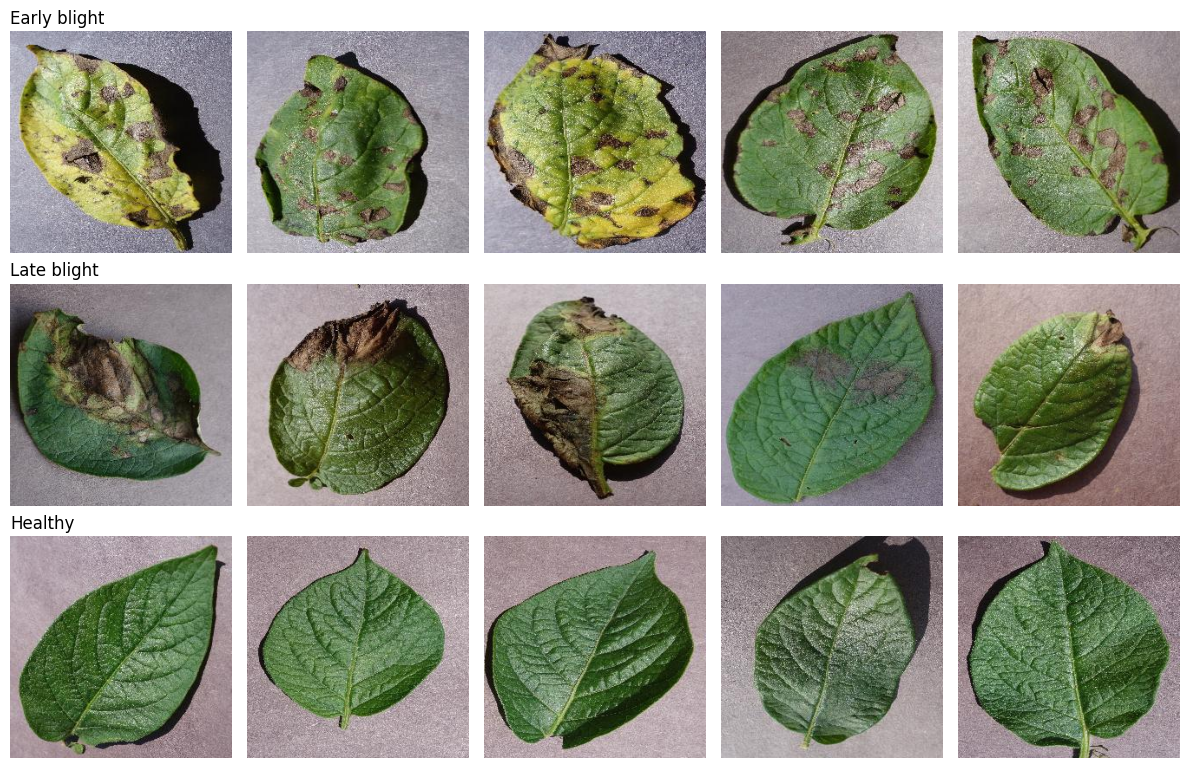

Most common original sizes: [((256, 256), 300)]


In [8]:
# Sample images per class
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(12, 2.6 * NUM_CLASSES))
axes = np.atleast_2d(axes)
for i, c in enumerate(CLASS_NAMES):
    files = random.sample(sorted((TRAIN_DIR / c).glob("*")), min(5, len(list((TRAIN_DIR / c).glob("*")))))
    for j, ax in enumerate(axes[i]):
        ax.axis("off")
        if j < len(files):
            ax.imshow(Image.open(files[j]).convert("RGB"))
            if j == 0: ax.set_title(DISPLAY[i], loc="left", fontsize=12)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "samples.png", dpi=100); plt.show()

# Original image sizes (all are resized to IMG_SIZE x IMG_SIZE in preprocessing)
sizes = Counter(Image.open(p).size for p in random.sample(splits["train"][0], min(300, len(splits["train"][0]))))
print("Most common original sizes:", sizes.most_common(5))

### Feature analysis — what story do the images tell?
We extract simple, interpretable features from each image to understand what separates the classes
(the CNN learns richer versions of the same cues):

1. **Average colour (R, G, B)** – healthy tissue is green; lesions are brown / yellow / black.
2. **Green-leaf pixel ratio** – share of pixels where green dominates red and blue: how much healthy tissue is left.
3. **Edge density** – share of strong-edge pixels: a proxy for spots, rings and texture created by lesions.

In [9]:
def image_features(path):
    img = Image.open(path).convert("RGB").resize((128, 128))
    a = np.asarray(img, dtype=np.float32); r, g, b = a[..., 0], a[..., 1], a[..., 2]
    edges = np.asarray(img.convert("L").filter(ImageFilter.FIND_EDGES), dtype=np.float32)
    return dict(mean_r=r.mean(), mean_g=g.mean(), mean_b=b.mean(),
                green_ratio=((g > r) & (g > b)).mean(),
                brightness=(0.299 * r + 0.587 * g + 0.114 * b).mean(),
                edge_density=(edges > 40).mean())

rows = []
for i, c in enumerate(CLASS_NAMES):
    files = sorted((TRAIN_DIR / c).glob("*")); random.shuffle(files)
    for f in files[:150]:
        rows.append({"class": DISPLAY[i], "class_raw": c, **image_features(f)})
feat = pd.DataFrame(rows)
display(feat.groupby("class")[["mean_r", "mean_g", "mean_b", "green_ratio", "brightness", "edge_density"]].mean().round(3))

,mean_r,mean_g,mean_b,green_ratio,brightness,edge_density
class,,,,,,
Early blight,136.511002,141.891006,116.512001,0.467,137.389008,0.297
Healthy,124.366997,131.899002,111.775002,0.508,127.352997,0.287
Late blight,118.406998,120.536003,105.957001,0.398,118.237000,0.244


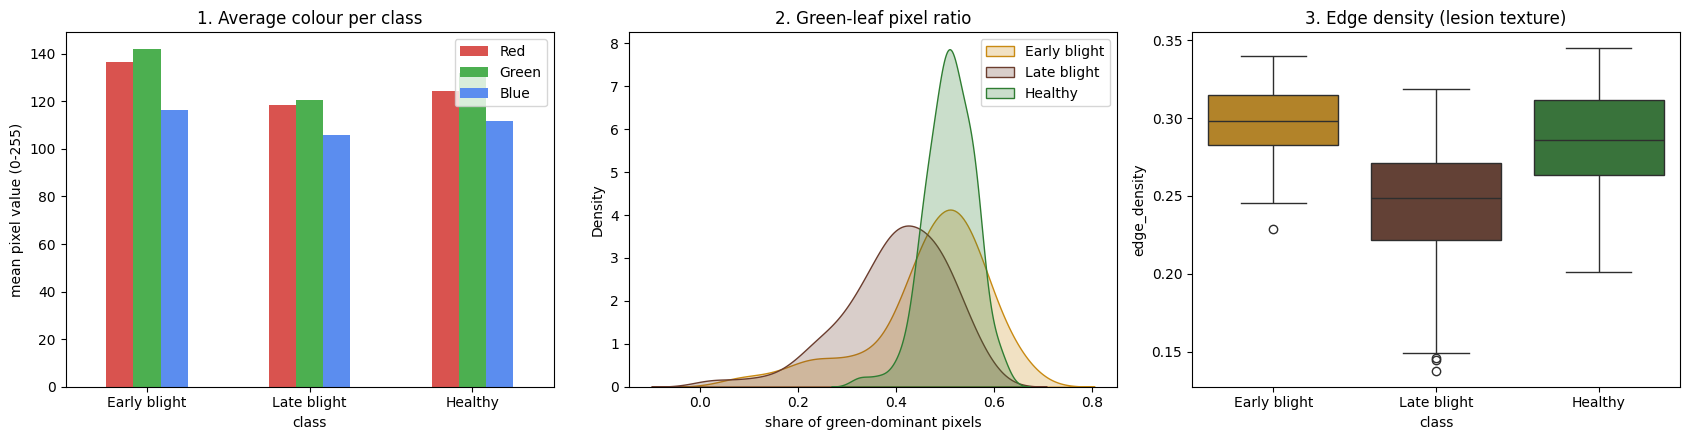

Green-minus-red gap per class:
 class
Early blight    5.4
Healthy         7.5
Late blight     2.1

Green ratio per class:
 class
Early blight    0.467
Healthy         0.508
Late blight     0.398

Edge density per class:
 class
Early blight    0.2970
Healthy         0.2868
Late blight     0.2438


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
m = feat.groupby("class")[["mean_r", "mean_g", "mean_b"]].mean().reindex(DISPLAY).rename(columns={"mean_r": "Red", "mean_g": "Green", "mean_b": "Blue"})
m.plot(kind="bar", ax=axes[0], color=["#d9534f", "#4caf50", "#5b8def"], rot=0)
axes[0].set_title("1. Average colour per class"); axes[0].set_ylabel("mean pixel value (0-255)")
for d, col in zip(DISPLAY, colors):
    sns.kdeplot(feat[feat["class"] == d].green_ratio, ax=axes[1], label=d, color=col, fill=True, alpha=.25, warn_singular=False)
axes[1].set_title("2. Green-leaf pixel ratio"); axes[1].set_xlabel("share of green-dominant pixels"); axes[1].legend()
sns.boxplot(data=feat, x="class", y="edge_density", order=DISPLAY, palette=colors, ax=axes[2], hue="class", legend=False)
axes[2].set_title("3. Edge density (lesion texture)")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "feature_analysis.png", dpi=120); plt.show()

g = feat.groupby("class").mean(numeric_only=True)
print("Green-minus-red gap per class:\n", (g.mean_g - g.mean_r).round(1).to_string())
print("\nGreen ratio per class:\n", g.green_ratio.round(3).to_string())
print("\nEdge density per class:\n", g.edge_density.round(4).to_string())

**Interpretation** (check the numbers printed above against these expectations for your data):

1. **Colour.** Healthy leaves show the largest green-minus-red gap. Blight destroys chlorophyll and leaves brown
   (early blight) or dark, water-soaked (late blight) tissue, so red rises relative to green. Colour is
   therefore an important signal, which is why we keep full RGB input rather than greyscale.
2. **Green-leaf ratio.** The healthy distribution sits furthest to the right (most of the leaf is still green);
   diseased classes shift left as lesions spread. Where the curves overlap (mild infections), colour alone
   is not enough and the model must also use shape and texture.
3. **Edge density.** Early blight creates many small concentric-ring spots and late blight large irregular
   patches with sharp borders, so diseased leaves usually have more edges than smooth healthy leaves.
   Convolution filters are exactly the tool to learn such local texture patterns.
4. **Class balance.** The class counts above show whether the dataset is imbalanced. If it is, we use class
   weights in training and report macro precision / recall / F1 so a minority class is not ignored.

In [11]:
# Save the same statistics the web UI shows (models/insights.json)
bins = np.linspace(0, 1, 21)
insights = {
    "class_names": CLASS_NAMES,
    "display_names": dict(zip(CLASS_NAMES, DISPLAY)),
    "counts": {"train": {c: int(counts.loc[d, "train"]) for c, d in zip(CLASS_NAMES, DISPLAY)},
               "test": {c: int(counts.loc[d, "test"]) for c, d in zip(CLASS_NAMES, DISPLAY)},
               "uploads": {c: 0 for c in CLASS_NAMES}},
    "feature_means": {c: {k: float(v) for k, v in feat[feat.class_raw == c].mean(numeric_only=True).items()} for c in CLASS_NAMES},
    "green_ratio_hist": {"bins": bins.round(2).tolist(),
                         "counts": {c: np.histogram(feat[feat.class_raw == c].green_ratio, bins=bins)[0].tolist() for c in CLASS_NAMES}},
    "samples_used": {c: int((feat.class_raw == c).sum()) for c in CLASS_NAMES},
}
(MODELS_DIR / "insights.json").write_text(json.dumps(insights, indent=2))

2671

## 4. Data preprocessing
Steps applied to every image (identical to `src/preprocessing.py`, used by the API):

1. **Decode + verify** – corrupt files were removed in section 2.
2. **Convert to RGB** – 3 channels even for PNG with alpha or greyscale images.
3. **Resize** to `128 × 128` – a fixed input size; small enough to train fast from scratch.
4. **Rescale** pixels from `[0, 255]` to `[0, 1]` – stabilises gradient descent.
5. **Data augmentation (training only)** – random flips, rotation, zoom, contrast, brightness. Leaves can appear
   at any orientation and lighting, and augmentation reduces over-fitting on a small dataset.
6. **One-hot labels**, shuffling, batching and prefetching with `tf.data`.
7. **Class weights** – inverse class frequency, to counter imbalance.

Class weights: {'Early blight': 0.717, 'Late blight': 0.717, 'Healthy': 4.736}


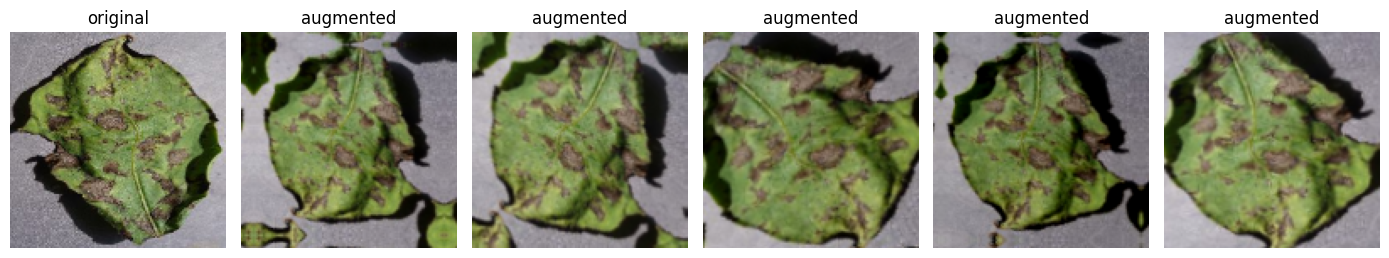

In [12]:
AUTOTUNE = tf.data.AUTOTUNE

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.1, value_range=(0.0, 1.0)),
], name="augmentation")

def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)   # decode, RGB
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))                                         # resize
    img = tf.cast(img, tf.float32) / 255.0                                                   # rescale
    return img, tf.one_hot(label, NUM_CLASSES)                                               # one-hot

def make_dataset(paths, labels, augment=False, shuffle=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle: ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(batch_size)
    if augment:
        ds = ds.map(lambda x, y: (tf.clip_by_value(augmentation(x, training=True), 0., 1.), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(*splits["train"], augment=True, shuffle=True)
val_ds = make_dataset(*splits["val"])
test_ds = make_dataset(*splits["test"])

tr_labels = splits["train"][1]
cnt = Counter(tr_labels)
CLASS_WEIGHTS = {i: len(tr_labels) / (NUM_CLASSES * cnt[i]) for i in range(NUM_CLASSES)}
print("Class weights:", {DISPLAY[k]: round(v, 3) for k, v in CLASS_WEIGHTS.items()})

# Visualise augmentation on one training image
x, _ = load_image(splits["train"][0][0], 0)
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(x); axes[0].set_title("original"); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(tf.clip_by_value(augmentation(x[None], training=True)[0], 0, 1)); ax.set_title("augmented"); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Model creation — custom CNN from scratch
No pretrained weights are used. Architecture: 4 convolutional blocks
`[Conv3×3 → BatchNorm → ReLU] ×2 → MaxPool → Dropout` with 32-64-128-256 filters,
then Global Average Pooling → Dense(256) → Dropout(0.4) → Softmax.

**Optimisation techniques**
* **L2 regularisation** (1e-4) on all kernels, **dropout** in every block and in the head
* **Batch normalisation** for faster, more stable training
* **Label smoothing** (0.05) to avoid over-confident predictions
* **Optimiser comparison** (Adam vs RMSprop vs SGD + Nesterov momentum) — a small hyper-parameter search
* **EarlyStopping** (restores best weights), **ReduceLROnPlateau**, **ModelCheckpoint**
* **Class weights** for imbalance

A **vanilla CNN** (no regularisation, no BN/dropout, plain SGD, no augmentation) is trained first as a baseline.

In [13]:
METRICS = lambda: ["accuracy", tf.keras.metrics.Precision(name="precision"),
                   tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.AUC(name="auc")]

def get_optimizer(name, lr):
    return {"adam": lambda: tf.keras.optimizers.Adam(lr),
            "rmsprop": lambda: tf.keras.optimizers.RMSprop(lr),
            "sgd": lambda: tf.keras.optimizers.SGD(lr, momentum=0.9, nesterov=True)}[name]()

def build_model(num_classes=NUM_CLASSES, l2=1e-4, dropout=0.4, filters=(32, 64, 128, 256),
                optimizer="adam", lr=1e-3):
    reg = regularizers.l2(l2) if l2 else None
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = inputs
    for i, f in enumerate(filters):
        for j in range(2):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False, kernel_regularizer=reg, name=f"conv{i+1}_{j+1}")(x)
            x = layers.BatchNormalization(name=f"bn{i+1}_{j+1}")(x)
            x = layers.Activation("relu", name=f"relu{i+1}_{j+1}")(x)
        x = layers.MaxPooling2D(name=f"pool{i+1}")(x)
        x = layers.Dropout(min(0.1 + 0.05 * i, 0.3), name=f"drop{i+1}")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=reg, name="dense")(x)
    x = layers.Dropout(dropout, name="head_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    model = tf.keras.Model(inputs, outputs, name="potato_leaf_cnn")
    model.compile(optimizer=get_optimizer(optimizer, lr),
                  loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05), metrics=METRICS())
    return model

def build_vanilla_model():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Flatten(), layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax")], name="vanilla_cnn")
    model.compile(optimizer=tf.keras.optimizers.SGD(1e-2), loss="categorical_crossentropy", metrics=METRICS())
    return model

def callbacks(ckpt=None, patience=8):
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)]
    if ckpt: cbs.append(tf.keras.callbacks.ModelCheckpoint(str(ckpt), monitor="val_loss", save_best_only=True))
    return cbs

build_model().summary()

Model: "potato_leaf_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_1 (BatchNormalization)      │ (None, 128, 128, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_1 (Activation)            │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_2 (BatchNormalization)      │ (None, 128, 128, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_2 (Activation)            │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_1 (BatchNormalization)      │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_1 (Activation)            │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_2 (BatchNormalization)      │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_2 (Activation)            │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_1 (BatchNormalization)      │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_1 (Activation)            │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_2 (Conv2D)                │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3_2 (BatchNormalization)      │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3_2 (Activation)            │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 16, 16, 128)    │             

 Total params: 1,241,699 (4.74 MB)

 Trainable params: 1,239,779 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [14]:
# ---- Baseline: vanilla CNN, no augmentation / regularisation ----
results = {}
if RUN_BASELINE:
    vanilla = build_vanilla_model()
    h_v = vanilla.fit(make_dataset(*splits["train"], shuffle=True), validation_data=val_ds,
                      epochs=BASELINE_EPOCHS, verbose=2)
    results["vanilla"] = h_v.history

Epoch 1/15
48/48 - 23s - 472ms/step - accuracy: 0.4781 - auc: 0.7371 - loss: 0.9044 - precision: 0.5874 - recall: 0.2922 - val_accuracy: 0.4644 - val_auc: 0.6133 - val_loss: 1.1983 - val_precision: 0.4644 - val_recall: 0.4644
Epoch 2/15
48/48 - 1s - 25ms/step - accuracy: 0.5757 - auc: 0.7840 - loss: 0.8625 - precision: 0.6536 - recall: 0.4223 - val_accuracy: 0.4644 - val_auc: 0.6806 - val_loss: 1.1579 - val_precision: 0.4644 - val_recall: 0.4644
Epoch 3/15
48/48 - 1s - 26ms/step - accuracy: 0.6766 - auc: 0.8417 - loss: 0.8020 - precision: 0.7287 - recall: 0.5332 - val_accuracy: 0.5139 - val_auc: 0.8135 - val_loss: 0.8035 - val_precision: 0.5329 - val_recall: 0.4768
Epoch 4/15
48/48 - 2s - 38ms/step - accuracy: 0.6819 - auc: 0.8564 - loss: 0.7291 - precision: 0.7149 - recall: 0.6162 - val_accuracy: 0.4737 - val_auc: 0.7712 - val_loss: 1.1666 - val_precision: 0.4737 - val_recall: 0.4737
Epoch 5/15
48/48 - 2s - 44ms/step - accuracy: 0.7742 - auc: 0.8929 - loss: 0.6291 - precision: 0.7966 

In [15]:
# ---- Hyper-parameter tuning: which optimiser / learning rate works best? ----
CANDIDATES = [("adam", 1e-3), ("rmsprop", 1e-3), ("sgd", 1e-2)]
search = []
if RUN_OPTIMIZER_SEARCH:
    for opt, lr in CANDIDATES:
        tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
        m = build_model(optimizer=opt, lr=lr)
        h = m.fit(train_ds, validation_data=val_ds, epochs=SEARCH_EPOCHS, class_weight=CLASS_WEIGHTS, verbose=0)
        search.append({"optimizer": opt, "lr": lr, "best_val_accuracy": max(h.history["val_accuracy"]),
                       "best_val_loss": min(h.history["val_loss"])})
        print(search[-1])
    search_df = pd.DataFrame(search).sort_values(["best_val_accuracy", "best_val_loss"], ascending=[False, True])
    display(search_df)
    BEST_OPT, BEST_LR = search_df.iloc[0].optimizer, float(search_df.iloc[0].lr)
else:
    BEST_OPT, BEST_LR = "adam", 1e-3
print("Selected optimiser:", BEST_OPT, "lr =", BEST_LR)

{'optimizer': 'adam', 'lr': 0.001, 'best_val_accuracy': 0.6315789222717285, 'best_val_loss': 0.9915059208869934}
{'optimizer': 'rmsprop', 'lr': 0.001, 'best_val_accuracy': 0.5851393342018127, 'best_val_loss': 1.1478441953659058}
{'optimizer': 'sgd', 'lr': 0.01, 'best_val_accuracy': 0.42105263471603394, 'best_val_loss': 1.700149416923523}


,optimizer,lr,best_val_accuracy,best_val_loss
0,adam,0.001,0.631579,0.991506
1,rmsprop,0.001,0.585139,1.147844
2,sgd,0.010,0.421053,1.700149


Selected optimiser: adam lr = 0.001


## 6. Train the final optimised model

Epoch 1/50


48/48 - 33s - 695ms/step - accuracy: 0.7643 - auc: 0.9117 - loss: 0.7848 - precision: 0.8057 - recall: 0.6992 - val_accuracy: 0.4644 - val_auc: 0.5975 - val_loss: 3.7660 - val_precision: 0.4644 - val_recall: 0.4644 - learning_rate: 0.0010
Epoch 2/50
48/48 - 20s - 417ms/step - accuracy: 0.8997 - auc: 0.9802 - loss: 0.5011 - precision: 0.9137 - recall: 0.8792 - val_accuracy: 0.4644 - val_auc: 0.5687 - val_loss: 4.1697 - val_precision: 0.4644 - val_recall: 0.4644 - learning_rate: 0.0010
Epoch 3/50
48/48 - 6s - 134ms/step - accuracy: 0.8280 - auc: 0.9408 - loss: 0.6356 - precision: 0.8427 - recall: 0.8001 - val_accuracy: 0.4644 - val_auc: 0.6253 - val_loss: 4.3758 - val_precision: 0.4644 - val_recall: 0.4644 - learning_rate: 0.0010
Epoch 4/50


48/48 - 9s - 181ms/step - accuracy: 0.8958 - auc: 0.9777 - loss: 0.4804 - precision: 0.9064 - recall: 0.8811 - val_accuracy: 0.5015 - val_auc: 0.8016 - val_loss: 1.7396 - val_precision: 0.5015 - val_recall: 0.5015 - learning_rate: 0.0010
Epoch 5/50


48/48 - 7s - 137ms/step - accuracy: 0.9376 - auc: 0.9910 - loss: 0.4222 - precision: 0.9399 - recall: 0.9349 - val_accuracy: 0.8483 - val_auc: 0.9189 - val_loss: 0.8715 - val_precision: 0.8505 - val_recall: 0.8452 - learning_rate: 0.0010
Epoch 6/50
48/48 - 8s - 168ms/step - accuracy: 0.9489 - auc: 0.9924 - loss: 0.3965 - precision: 0.9541 - recall: 0.9389 - val_accuracy: 0.7214 - val_auc: 0.8849 - val_loss: 0.9681 - val_precision: 0.7281 - val_recall: 0.7214 - learning_rate: 0.0010
Epoch 7/50
48/48 - 7s - 137ms/step - accuracy: 0.9402 - auc: 0.9898 - loss: 0.4181 - precision: 0.9485 - recall: 0.9303 - val_accuracy: 0.6935 - val_auc: 0.8702 - val_loss: 1.0905 - val_precision: 0.6935 - val_recall: 0.6935 - learning_rate: 0.0010
Epoch 8/50

Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
48/48 - 8s - 170ms/step - accuracy: 0.9469 - auc: 0.9945 - loss: 0.3783 - precision: 0.9536 - recall: 0.9409 - val_accuracy: 0.4644 - val_auc: 0.7077 - val_loss: 3.2326 - val_p

48/48 - 11s - 229ms/step - accuracy: 0.9562 - auc: 0.9933 - loss: 0.3857 - precision: 0.9599 - recall: 0.9529 - val_accuracy: 0.9009 - val_auc: 0.9801 - val_loss: 0.4900 - val_precision: 0.9003 - val_recall: 0.8947 - learning_rate: 5.0000e-04
Epoch 11/50


48/48 - 12s - 259ms/step - accuracy: 0.9177 - auc: 0.9806 - loss: 0.4497 - precision: 0.9338 - recall: 0.8891 - val_accuracy: 0.9257 - val_auc: 0.9858 - val_loss: 0.4501 - val_precision: 0.9255 - val_recall: 0.9226 - learning_rate: 5.0000e-04
Epoch 12/50


48/48 - 7s - 140ms/step - accuracy: 0.9548 - auc: 0.9942 - loss: 0.3769 - precision: 0.9603 - recall: 0.9482 - val_accuracy: 0.9783 - val_auc: 0.9991 - val_loss: 0.3250 - val_precision: 0.9813 - val_recall: 0.9752 - learning_rate: 5.0000e-04
Epoch 13/50
48/48 - 10s - 209ms/step - accuracy: 0.9635 - auc: 0.9951 - loss: 0.3571 - precision: 0.9704 - recall: 0.9575 - val_accuracy: 0.9350 - val_auc: 0.9881 - val_loss: 0.4347 - val_precision: 0.9408 - val_recall: 0.9350 - learning_rate: 5.0000e-04
Epoch 14/50
48/48 - 8s - 171ms/step - accuracy: 0.9781 - auc: 0.9986 - loss: 0.3269 - precision: 0.9813 - recall: 0.9754 - val_accuracy: 0.9752 - val_auc: 0.9985 - val_loss: 0.3354 - val_precision: 0.9781 - val_recall: 0.9659 - learning_rate: 5.0000e-04
Epoch 15/50


48/48 - 7s - 141ms/step - accuracy: 0.9754 - auc: 0.9981 - loss: 0.3325 - precision: 0.9773 - recall: 0.9734 - val_accuracy: 0.9814 - val_auc: 0.9992 - val_loss: 0.3225 - val_precision: 0.9814 - val_recall: 0.9814 - learning_rate: 5.0000e-04
Epoch 16/50
48/48 - 8s - 174ms/step - accuracy: 0.9475 - auc: 0.9930 - loss: 0.3683 - precision: 0.9548 - recall: 0.9396 - val_accuracy: 0.8978 - val_auc: 0.9790 - val_loss: 0.4786 - val_precision: 0.9019 - val_recall: 0.8824 - learning_rate: 5.0000e-04
Epoch 17/50
48/48 - 9s - 178ms/step - accuracy: 0.9668 - auc: 0.9963 - loss: 0.3409 - precision: 0.9680 - recall: 0.9635 - val_accuracy: 0.9659 - val_auc: 0.9981 - val_loss: 0.3632 - val_precision: 0.9659 - val_recall: 0.9659 - learning_rate: 5.0000e-04
Epoch 18/50

Epoch 18: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
48/48 - 10s - 203ms/step - accuracy: 0.9661 - auc: 0.9964 - loss: 0.3447 - precision: 0.9712 - recall: 0.9622 - val_accuracy: 0.8359 - val_auc: 0.9566 - val_los

48/48 - 9s - 183ms/step - accuracy: 0.9748 - auc: 0.9983 - loss: 0.3263 - precision: 0.9767 - recall: 0.9734 - val_accuracy: 0.9969 - val_auc: 0.9997 - val_loss: 0.2956 - val_precision: 0.9969 - val_recall: 0.9907 - learning_rate: 2.5000e-04
Epoch 20/50
48/48 - 8s - 161ms/step - accuracy: 0.9582 - auc: 0.9947 - loss: 0.3565 - precision: 0.9651 - recall: 0.9548 - val_accuracy: 0.7245 - val_auc: 0.8944 - val_loss: 0.9938 - val_precision: 0.7245 - val_recall: 0.7245 - learning_rate: 2.5000e-04
Epoch 21/50
48/48 - 9s - 178ms/step - accuracy: 0.9768 - auc: 0.9982 - loss: 0.3196 - precision: 0.9780 - recall: 0.9748 - val_accuracy: 0.8576 - val_auc: 0.9620 - val_loss: 0.5866 - val_precision: 0.8616 - val_recall: 0.8483 - learning_rate: 2.5000e-04
Epoch 22/50

Epoch 22: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
48/48 - 8s - 176ms/step - accuracy: 0.9761 - auc: 0.9979 - loss: 0.3106 - precision: 0.9813 - recall: 0.9748 - val_accuracy: 0.9690 - val_auc: 0.9987 - val_loss

48/48 - 8s - 172ms/step - accuracy: 0.9708 - auc: 0.9964 - loss: 0.3264 - precision: 0.9746 - recall: 0.9675 - val_accuracy: 0.9969 - val_auc: 1.0000 - val_loss: 0.2799 - val_precision: 0.9969 - val_recall: 0.9969 - learning_rate: 1.2500e-04
Epoch 24/50
48/48 - 7s - 139ms/step - accuracy: 0.9814 - auc: 0.9983 - loss: 0.3115 - precision: 0.9853 - recall: 0.9788 - val_accuracy: 0.9721 - val_auc: 0.9988 - val_loss: 0.3189 - val_precision: 0.9720 - val_recall: 0.9659 - learning_rate: 1.2500e-04
Epoch 25/50
48/48 - 8s - 169ms/step - accuracy: 0.9774 - auc: 0.9982 - loss: 0.3120 - precision: 0.9800 - recall: 0.9741 - val_accuracy: 0.9907 - val_auc: 0.9998 - val_loss: 0.2973 - val_precision: 0.9907 - val_recall: 0.9907 - learning_rate: 1.2500e-04
Epoch 26/50

Epoch 26: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
48/48 - 10s - 216ms/step - accuracy: 0.9814 - auc: 0.9989 - loss: 0.3097 - precision: 0.9833 - recall: 0.9781 - val_accuracy: 0.9721 - val_auc: 0.9990 - val_loss

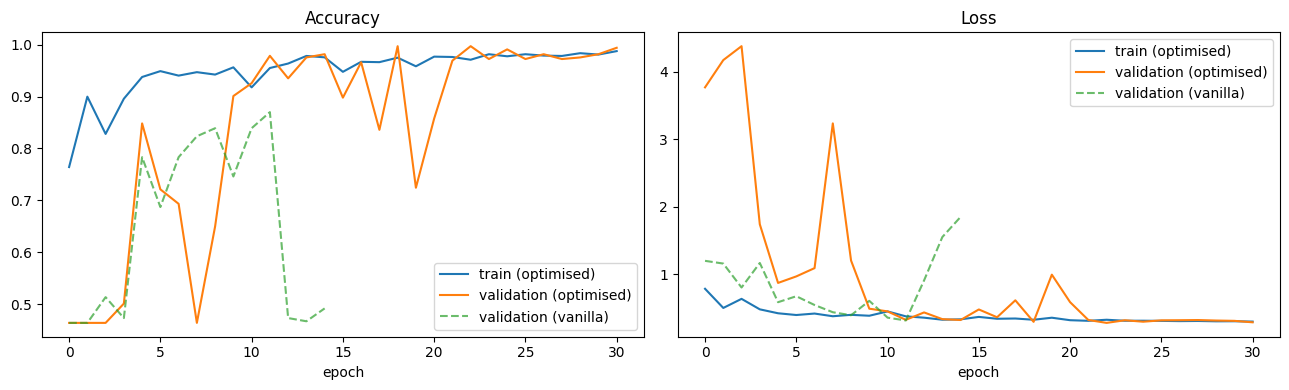

In [16]:
tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
model = build_model(optimizer=BEST_OPT, lr=BEST_LR)
t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=CLASS_WEIGHTS,
                    callbacks=callbacks(MODELS_DIR / "best_checkpoint.h5"), verbose=2)
print(f"Training time: {(time.time() - t0) / 60:.1f} min, epochs run: {len(history.history['loss'])}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, k in zip(axes, ["accuracy", "loss"]):
    ax.plot(history.history[k], label="train (optimised)"); ax.plot(history.history["val_" + k], label="validation (optimised)")
    if "vanilla" in results:
        ax.plot(results["vanilla"]["val_" + k], "--", label="validation (vanilla)", alpha=.7)
    ax.set_title(k.capitalize()); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.savefig(PLOTS_DIR / "training_curves.png", dpi=120); plt.show()

## 7. Model evaluation on the held-out test set
Metrics: **accuracy, loss, precision, recall, F1** (macro and weighted), **ROC-AUC**, per-class report and the
**confusion matrix**. The test set was never used for training or model selection.

In [17]:
def evaluate(model, ds):
    res = model.evaluate(ds, verbose=0, return_dict=True)
    y_true, y_prob = [], []
    for x, y in ds:
        y_prob.append(model.predict(x, verbose=0)); y_true.append(np.argmax(y.numpy(), 1))
    y_true, y_prob = np.concatenate(y_true), np.concatenate(y_prob)
    y_pred = y_prob.argmax(1)
    m = {"loss": float(res["loss"]), "accuracy": float(accuracy_score(y_true, y_pred)),
         "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
         "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
         "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
         "precision_weighted": float(precision_score(y_true, y_pred, average="weighted", zero_division=0)),
         "recall_weighted": float(recall_score(y_true, y_pred, average="weighted", zero_division=0)),
         "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
         "confusion_matrix": confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES)).tolist(),
         "per_class": classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASS_NAMES,
                                            output_dict=True, zero_division=0),
         "n_samples": int(len(y_true))}
    try: m["roc_auc_ovr"] = float(roc_auc_score(np.eye(NUM_CLASSES)[y_true], y_prob, average="macro", multi_class="ovr"))
    except ValueError: pass
    return m, y_true, y_pred, y_prob

test_metrics, y_true, y_pred, y_prob = evaluate(model, test_ds)
summary_keys = ["accuracy", "loss", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "roc_auc_ovr"]
table = {"Optimised CNN": {k: test_metrics.get(k) for k in summary_keys}}
if RUN_BASELINE:
    van_metrics = evaluate(vanilla, test_ds)[0]
    table["Vanilla CNN"] = {k: van_metrics.get(k) for k in summary_keys}
display(pd.DataFrame(table).round(4))
print(classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=DISPLAY, digits=4, zero_division=0))

,Optimised CNN,Vanilla CNN
accuracy,0.9876,0.4830
loss,0.2936,1.8776
precision_macro,0.9593,0.6073
recall_macro,0.9911,0.4080
f1_macro,0.9740,0.3110
f1_weighted,0.9878,0.3297
roc_auc_ovr,0.9998,0.9122


              precision    recall  f1-score   support

Early blight     0.9934    1.0000    0.9967       150
 Late blight     1.0000    0.9733    0.9865       150
     Healthy     0.8846    1.0000    0.9388        23

    accuracy                         0.9876       323
   macro avg     0.9593    0.9911    0.9740       323
weighted avg     0.9887    0.9876    0.9878       323



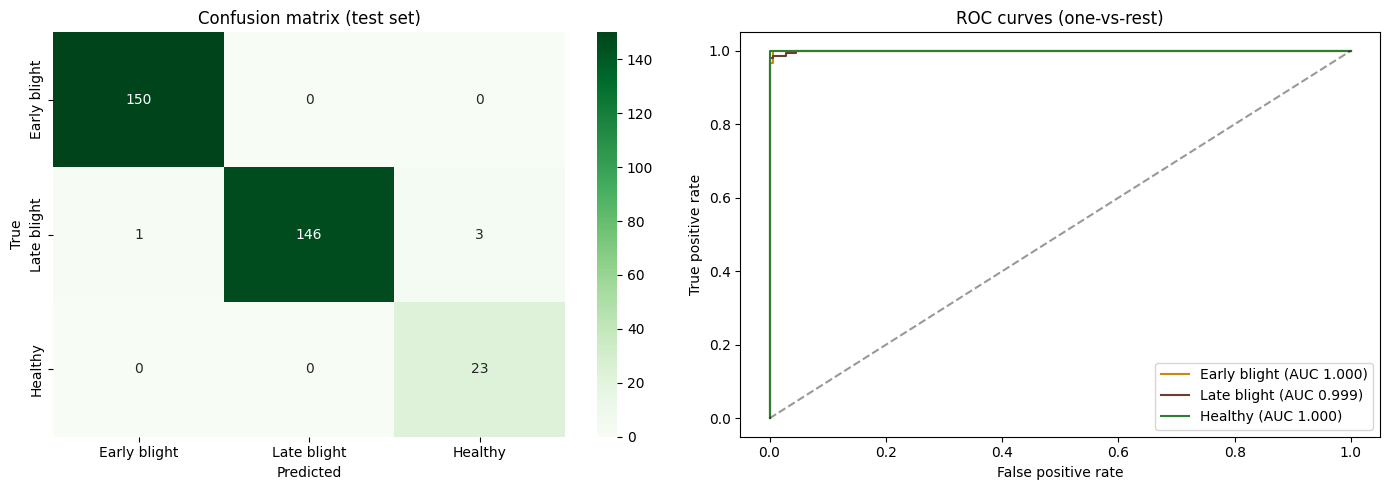

In [18]:
cm = np.array(test_metrics["confusion_matrix"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=DISPLAY, yticklabels=DISPLAY, ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True"); axes[0].set_title("Confusion matrix (test set)")
for i in range(NUM_CLASSES):
    if (y_true == i).any() and (y_true != i).any():
        fpr, tpr, _ = roc_curve(y_true == i, y_prob[:, i])
        axes[1].plot(fpr, tpr, color=colors[i], label=f"{DISPLAY[i]} (AUC {roc_auc_score(y_true == i, y_prob[:, i]):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4); axes[1].set_title("ROC curves (one-vs-rest)")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].legend()
plt.tight_layout(); plt.savefig(PLOTS_DIR / "confusion_matrix.png", dpi=120); plt.show()

**Reading the results.** Accuracy gives the overall hit-rate; macro precision / recall / F1 weigh every class
equally, so they reveal whether a minority class is being missed. In the confusion matrix, most errors (if any)
are expected between *Early blight* and *Late blight* because both produce brown lesions; healthy leaves are
the easiest to separate (see the green-ratio analysis). Compare the optimised model with the vanilla baseline:
regularisation, augmentation and early stopping should give a higher test F1 and a smaller train/validation gap.

## 8. Save the model and artefacts to Google Drive

In [19]:
MODEL_PATH = MODELS_DIR / "potato_cnn.h5"
model.save(MODEL_PATH)
(MODELS_DIR / "class_names.json").write_text(json.dumps(CLASS_NAMES, indent=2))
(MODELS_DIR / "metrics.json").write_text(json.dumps({
    "saved_at": datetime.now(timezone.utc).isoformat(), "model_file": MODEL_PATH.name,
    "tensorflow_version": tf.__version__, "optimizer": BEST_OPT, "learning_rate": BEST_LR,
    "img_size": IMG_SIZE, "epochs_run": len(history.history["loss"]),
    "optimizer_search": search, "baseline_metrics": table.get("Vanilla CNN"),
    "metrics": test_metrics}, indent=2))
print("Saved to Drive:")
for p in sorted(MODELS_DIR.rglob("*")): print("  ", p.relative_to(PROJECT))

Saved to Drive:
   models/best_checkpoint.h5
   models/class_names.json
   models/insights.json
   models/metrics.json
   models/plots
   models/plots/class_distribution.png
   models/plots/confusion_matrix.png
   models/plots/feature_analysis.png
   models/plots/samples.png
   models/plots/training_curves.png
   models/potato_cnn.h5


## 9. Prediction functions
`predict_image` applies exactly the same preprocessing as training and returns the class + confidence.
The same logic lives in `src/prediction.py` for the API.

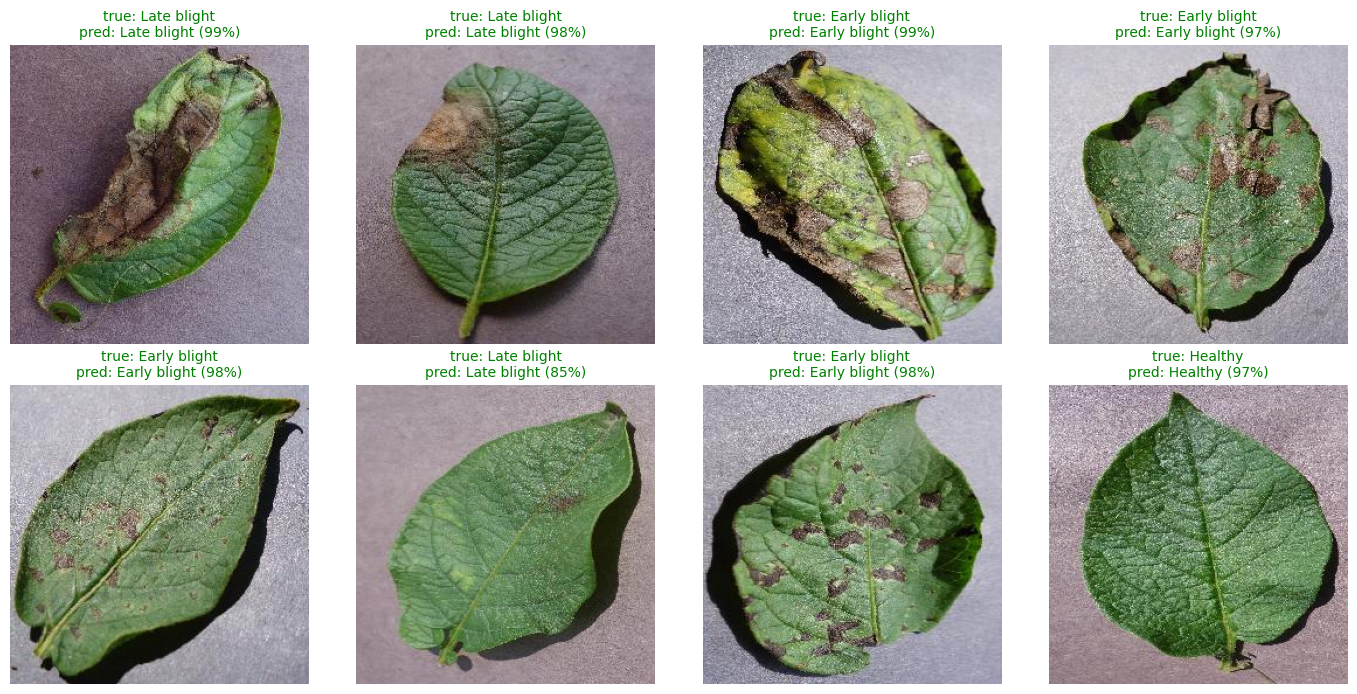

{'class': 'Late blight', 'confidence': 0.9901667237281799, 'probabilities': {'Early blight': 0.0041, 'Late blight': 0.9902, 'Healthy': 0.0057}}


In [20]:
_loaded = tf.keras.models.load_model(str(MODEL_PATH), compile=False)   # reload from disk to prove the file works
_classes = json.loads((MODELS_DIR / "class_names.json").read_text())

def preprocess_image(path_or_bytes):
    img = Image.open(path_or_bytes).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.expand_dims(np.asarray(img, dtype=np.float32) / 255.0, 0)

def predict_image(path, model=_loaded):
    probs = model.predict(preprocess_image(path), verbose=0)[0]
    i = int(probs.argmax())
    return {"class": pretty(_classes[i]), "confidence": float(probs[i]),
            "probabilities": {pretty(c): round(float(p), 4) for c, p in zip(_classes, probs)}}

test_paths, test_labels = splits["test"]
pick = random.sample(range(len(test_paths)), min(8, len(test_paths)))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, k in zip(axes.flat, pick):
    r = predict_image(test_paths[k]); true = DISPLAY[test_labels[k]]
    ax.imshow(Image.open(test_paths[k]).convert("RGB")); ax.axis("off")
    ax.set_title(f"true: {true}\npred: {r['class']} ({r['confidence']:.0%})", color="green" if r["class"] == true else "red", fontsize=10)
plt.tight_layout(); plt.show()
print(predict_image(test_paths[pick[0]]))

## 10. Retraining with the saved custom model as the pre-trained model
This is the same logic as `src/retrain.py` (triggered by the **Retrain** button in the web app):

1. New labelled images are placed in `DRIVE_PROJECT_DIR/new_data/<class_name>/` (upload them to Drive, or they come from the app's bulk upload).
2. They go through the same preprocessing.
3. The **saved `potato_cnn.h5` is loaded as the pre-trained model** and fine-tuned on old + new data with a lower learning rate and early stopping.
4. Old vs new model are compared on the test set; the new model replaces the old one only if it is not worse.

If `new_data/` is empty, this demo uses the validation images as "new data" so the cell always runs.

In [21]:
def retrain_model(new_data_dir=NEW_DATA_DIR, epochs=5, lr=1e-4):
    new_paths, new_labels = [], []
    for i, c in enumerate(CLASS_NAMES):
        for p in sorted(Path(new_data_dir, c).glob("*")) if Path(new_data_dir, c).exists() else []:
            if is_image(p): new_paths.append(str(p)); new_labels.append(i)
    if not new_paths:
        print("new_data/ is empty -> using validation images as the 'new' data for this demo")
        new_paths, new_labels = splits["val"]
    print(f"New images: {len(new_paths)}")

    base = tf.keras.models.load_model(str(MODEL_PATH), compile=False)        # custom model as pre-trained model
    base.compile(optimizer=tf.keras.optimizers.Adam(lr),
                 loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05), metrics=METRICS())
    old_metrics = evaluate(base, test_ds)[0]

    paths = splits["train"][0] + new_paths; labels = splits["train"][1] + new_labels
    base.fit(make_dataset(paths, labels, augment=True, shuffle=True), validation_data=val_ds, epochs=epochs,
             class_weight=CLASS_WEIGHTS, callbacks=callbacks(patience=3), verbose=2)
    new_metrics = evaluate(base, test_ds)[0]

    cmp = pd.DataFrame({"before": {k: old_metrics.get(k) for k in summary_keys},
                        "after retraining": {k: new_metrics.get(k) for k in summary_keys}}).round(4)
    display(cmp)
    version = datetime.now().strftime("%Y%m%d_%H%M%S")
    (MODELS_DIR / "archive").mkdir(exist_ok=True)
    base.save(MODELS_DIR / "archive" / f"potato_cnn_retrained_{version}.h5")
    if new_metrics["accuracy"] >= old_metrics["accuracy"] - 0.01:
        shutil.copy(MODEL_PATH, MODELS_DIR / "archive" / f"potato_cnn_before_{version}.h5")
        base.save(MODEL_PATH)
        print("✅ Retrained model promoted to", MODEL_PATH)
    else:
        print("Retrained model was worse; kept the previous model (candidate saved in archive/).")
    return base, cmp

retrained_model, retrain_comparison = retrain_model(epochs=3)

new_data/ is empty -> using validation images as the 'new' data for this demo
New images: 323
Epoch 1/3
58/58 - 47s - 815ms/step - accuracy: 0.9792 - auc: 0.9975 - loss: 0.3160 - precision: 0.9818 - recall: 0.9754 - val_accuracy: 0.9752 - val_auc: 0.9993 - val_loss: 0.3098 - val_precision: 0.9783 - val_recall: 0.9752 - learning_rate: 1.0000e-04
Epoch 2/3
58/58 - 10s - 175ms/step - accuracy: 0.9841 - auc: 0.9991 - loss: 0.3005 - precision: 0.9863 - recall: 0.9831 - val_accuracy: 0.9969 - val_auc: 0.9998 - val_loss: 0.2847 - val_precision: 0.9969 - val_recall: 0.9969 - learning_rate: 1.0000e-04
Epoch 3/3
58/58 - 8s - 144ms/step - accuracy: 0.9803 - auc: 0.9983 - loss: 0.3063 - precision: 0.9840 - recall: 0.9781 - val_accuracy: 0.9969 - val_auc: 0.9999 - val_loss: 0.2794 - val_precision: 0.9969 - val_recall: 0.9969 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 3.


,before,after retraining
accuracy,0.9876,0.9907
loss,0.2936,0.2904
precision_macro,0.9593,0.9711
recall_macro,0.9911,0.9933
f1_macro,0.9740,0.9816
f1_weighted,0.9878,0.9908
roc_auc_ovr,0.9998,0.9998


✅ Retrained model promoted to /content/drive/MyDrive/potato_leaf_mlops/models/potato_cnn.h5


## 11. Export for the GitHub repo / API
Everything is already on Drive in `potato_leaf_mlops/`. Copy into the repo:

| Drive | Repo |
|---|---|
| `models/potato_cnn.h5`, `class_names.json`, `metrics.json`, `insights.json`, `plots/` | `models/` |
| `data/train/`, `data/test/` | `data/train/`, `data/test/` |

The cell below also builds a single zip on Drive you can download.

In [22]:
export = PROJECT / "export_for_repo.zip"
with zipfile.ZipFile(export, "w", zipfile.ZIP_DEFLATED) as z:
    for f in ["potato_cnn.h5", "class_names.json", "metrics.json", "insights.json"]:
        if (MODELS_DIR / f).exists(): z.write(MODELS_DIR / f, f"models/{f}")
    for p in PLOTS_DIR.glob("*.png"): z.write(p, f"models/plots/{p.name}")
    for split in ("train", "test"):
        for p in (DATA_DIR / split).rglob("*"):
            if p.is_file(): z.write(p, f"data/{split}/{p.relative_to(DATA_DIR / split)}")
print("Export written to", export, f"({export.stat().st_size / 1e6:.1f} MB)")
if IN_COLAB:
    print("Download it from Drive, or run: from google.colab import files; files.download(str(export))")

Export written to /content/drive/MyDrive/potato_leaf_mlops/export_for_repo.zip (49.4 MB)
Download it from Drive, or run: from google.colab import files; files.download(str(export))
